# **Customer Churn Prediction**

Project Goal

Our project will predict whether a customer will:

Stay with the company

Churn (leave the company)

**1 -> churned / 0 -> stayed**

In [44]:
import pandas as pd

In [45]:
import numpy as np

In [46]:
data = pd.read_excel('dataset/E Commerce Dataset.xlsx')

In [47]:
data.head()

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


In [48]:
data.columns

Index(['CustomerID', 'Churn', 'Tenure', 'PreferredLoginDevice', 'CityTier',
       'WarehouseToHome', 'PreferredPaymentMode', 'Gender', 'HourSpendOnApp',
       'NumberOfDeviceRegistered', 'PreferedOrderCat', 'SatisfactionScore',
       'MaritalStatus', 'NumberOfAddress', 'Complain',
       'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount',
       'DaySinceLastOrder', 'CashbackAmount'],
      dtype='str')

In [49]:
data.shape

(5630, 20)

In [50]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   str    
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   str    
 7   Gender                       5630 non-null   str    
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   str    
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   str    
 13  NumberOfAddress              

In [51]:
data.isnull().sum()

CustomerID                       0
Churn                            0
Tenure                         264
PreferredLoginDevice             0
CityTier                         0
WarehouseToHome                251
PreferredPaymentMode             0
Gender                           0
HourSpendOnApp                 255
NumberOfDeviceRegistered         0
PreferedOrderCat                 0
SatisfactionScore                0
MaritalStatus                    0
NumberOfAddress                  0
Complain                         0
OrderAmountHikeFromlastYear    265
CouponUsed                     256
OrderCount                     258
DaySinceLastOrder              307
CashbackAmount                   0
dtype: int64

In [52]:
data.duplicated().sum()

np.int64(0)

In [53]:
data['Churn'].value_counts()

Churn
0    4682
1     948
Name: count, dtype: int64

In [54]:
data['Churn'].value_counts(normalize=True)*100

Churn
0    83.161634
1    16.838366
Name: proportion, dtype: float64

In [55]:
data.describe()

,CustomerID,Churn,Tenure,CityTier,WarehouseToHome,HourSpendOnApp,NumberOfDeviceRegistered,SatisfactionScore,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
count,5630.000000,5630.000000,5366.000000,5630.000000,5379.000000,5375.000000,5630.000000,5630.000000,5630.000000,5630.000000,5365.000000,5374.000000,5372.000000,5323.000000,5630.000000
mean,52815.500000,0.168384,10.189899,1.654707,15.639896,2.931535,3.688988,3.066785,4.214032,0.284902,15.707922,1.751023,3.008004,4.543491,177.223030
std,1625.385339,0.374240,8.557241,0.915389,8.531475,0.721926,1.023999,1.380194,2.583586,0.451408,3.675485,1.894621,2.939680,3.654433,49.207036
min,50001.000000,0.000000,0.000000,1.000000,5.000000,0.000000,1.000000,1.000000,1.000000,0.000000,11.000000,0.000000,1.000000,0.000000,0.000000
25%,51408.250000,0.000000,2.000000,1.000000,9.000000,2.000000,3.000000,2.000000,2.000000,0.000000,13.000000,1.000000,1.000000,2.000000,145.770000
50%,52815.500000,0.000000,9.000000,1.000000,14.000000,3.000000,4.000000,3.000000,3.000000,0.000000,15.000000,1.000000,2.000000,3.000000,163.280000
75%,54222.750000,0.000000,16.000000,3.000000,20.000000,3.000000,4.000000,4.000000,6.000000,1.000000,18.000000,2.000000,3.000000,7.000000,196.392500
max,55630.000000,1.000000,61.000000,3.000000,127.000000,5.000000,6.000000,5.000000,22.000000,1.000000,26.000000,16.000000,16.000000,46.000000,324.990000


**Handle Missing Values**

For this project, we'll use the **median** for numerical columns.

Why are we doing this?

For example: Tenure 4,
8,
10,
NaN,
12,

If the median is 9, we'll replace: NaN → 9

In [56]:
# Get numerical columns
num_cols = data.select_dtypes(include='number').columns

In [57]:
num_cols

Index(['CustomerID', 'Churn', 'Tenure', 'CityTier', 'WarehouseToHome',
       'HourSpendOnApp', 'NumberOfDeviceRegistered', 'SatisfactionScore',
       'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear',
       'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount'],
      dtype='str')

In [58]:
# Remove ID and churn
num_cols = data.select_dtypes(include='number').columns.drop(['CustomerID','Churn'])
print(num_cols)

Index(['Tenure', 'CityTier', 'WarehouseToHome', 'HourSpendOnApp',
       'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress',
       'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount',
       'DaySinceLastOrder', 'CashbackAmount'],
      dtype='str')


In [59]:
# Fill missing values with median
for i in num_cols:
    data[i] = data[i].fillna(data[i].median())

In [60]:
data.isnull().sum()

CustomerID                     0
Churn                          0
Tenure                         0
PreferredLoginDevice           0
CityTier                       0
WarehouseToHome                0
PreferredPaymentMode           0
Gender                         0
HourSpendOnApp                 0
NumberOfDeviceRegistered       0
PreferedOrderCat               0
SatisfactionScore              0
MaritalStatus                  0
NumberOfAddress                0
Complain                       0
OrderAmountHikeFromlastYear    0
CouponUsed                     0
OrderCount                     0
DaySinceLastOrder              0
CashbackAmount                 0
dtype: int64

**EDA (Exploratory Data Analysis).**

In [61]:
import seaborn as sns

In [62]:
import matplotlib.pyplot as plt

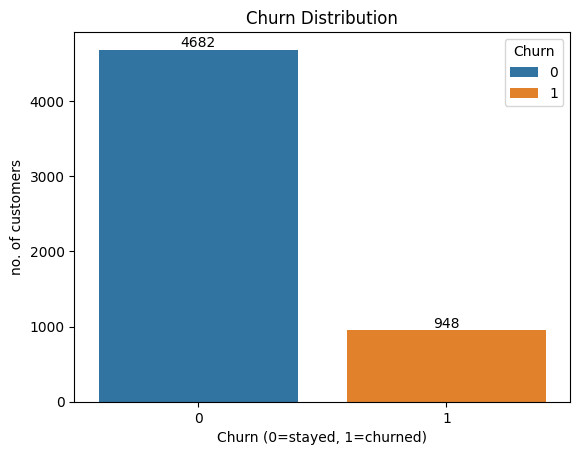

In [63]:
# Churn Distribution -> First, let's visualize how many customers stayed vs churned.
a1 = sns.countplot(x='Churn', data=data, hue='Churn') #hue = color each category churn wise
plt.xlabel("Churn (0=stayed, 1=churned)")
plt.ylabel("no. of customers")
plt.title("Churn Distribution")

for i in a1.containers:
    a1.bar_label(i)

plt.show()

In [64]:
# Columns that are related to churn
data.corr(numeric_only=True)['Churn'].sort_values(ascending=False)

Churn                          1.000000
Complain                       0.250188
NumberOfDeviceRegistered       0.107939
SatisfactionScore              0.105481
CityTier                       0.084703
WarehouseToHome                0.069544
NumberOfAddress                0.043931
HourSpendOnApp                 0.018816
CouponUsed                    -0.001430
OrderAmountHikeFromlastYear   -0.007075
CustomerID                    -0.019083
OrderCount                    -0.024038
CashbackAmount                -0.154118
DaySinceLastOrder             -0.155871
Tenure                        -0.337831
Name: Churn, dtype: float64

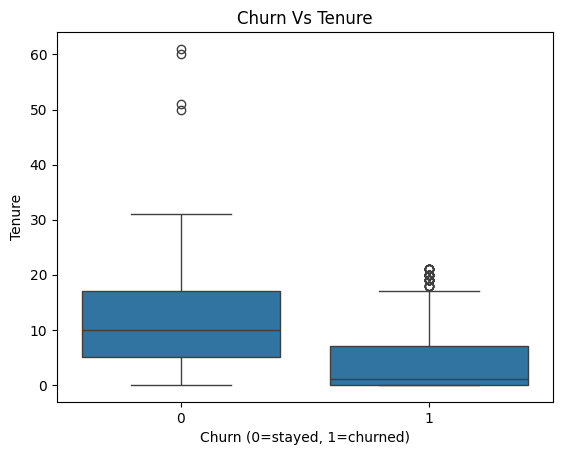

In [65]:
sns.boxplot(x='Churn', y='Tenure',data=data)
plt.title("Churn Vs Tenure")
plt.xlabel("Churn (0=stayed, 1=churned)")
plt.ylabel("Tenure")
plt.show()

# Customers with shorter tenure appear more likely to churn.

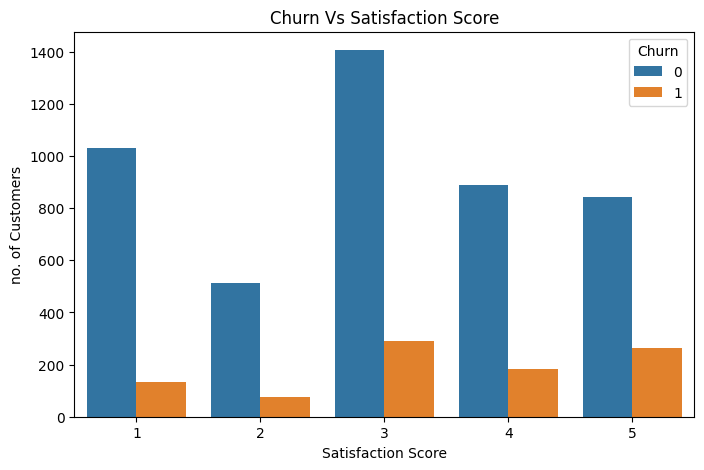

In [66]:
# Churn vs Satisfaction Score
plt.figure(figsize=(8,5))
sns.countplot(x='SatisfactionScore',hue='Churn',data=data)
plt.title("Churn Vs Satisfaction Score")
plt.xlabel("Satisfaction Score")
plt.ylabel("no. of Customers")
plt.show()

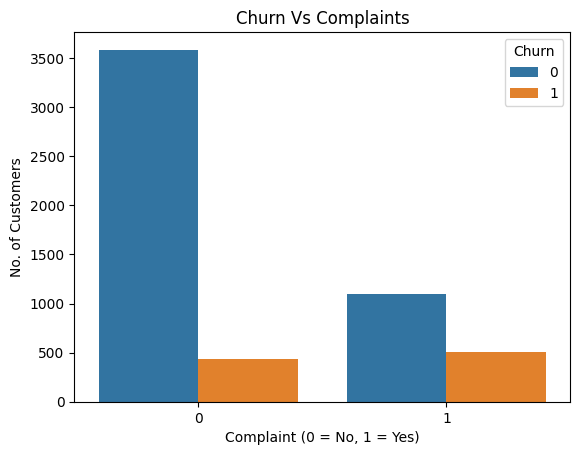

In [67]:
# Churn vs Complaints

sns.countplot(x='Complain',hue='Churn',data=data)
plt.title("Churn Vs Complaints")
plt.xlabel("Complaint (0 = No, 1 = Yes)")
plt.ylabel("No. of Customers")
plt.show()

In [68]:
# Churn rate = churned customers / total customers × 100
churn_rate = data.groupby('SatisfactionScore')['Churn'].mean() * 100
print(churn_rate)

SatisfactionScore
1    11.512027
2    12.627986
3    17.196702
4    17.132216
5    23.826715
Name: Churn, dtype: float64


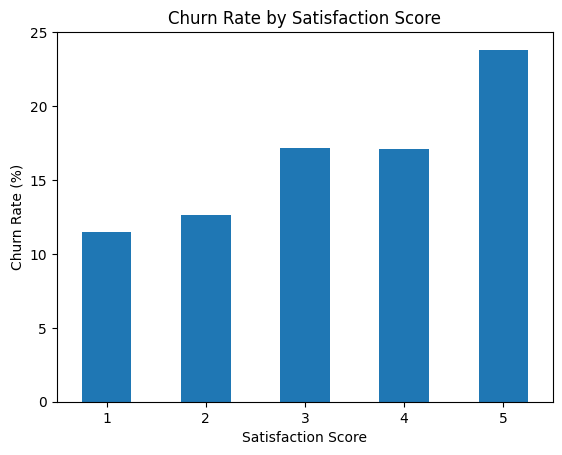

In [69]:
churn_rate.plot(kind='bar')
plt.title("Churn Rate by Satisfaction Score")
plt.xlabel("Satisfaction Score")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)
plt.show()

In [70]:
complain_churn_rate = data.groupby('Complain')['Churn'].mean() * 100
print(complain_churn_rate)

Complain
0    10.928962
1    31.670823
Name: Churn, dtype: float64


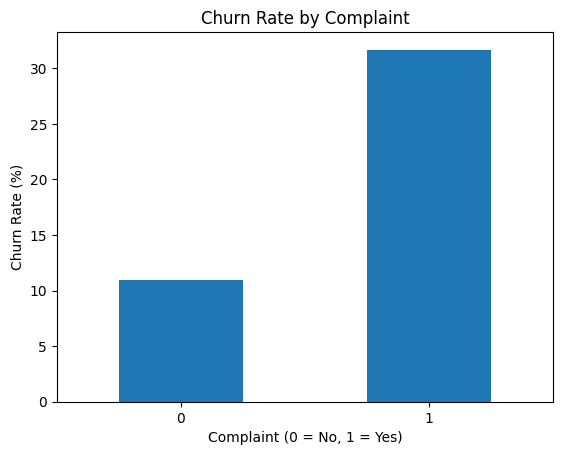

In [71]:
complain_churn_rate.plot(kind='bar')

plt.title('Churn Rate by Complaint')
plt.xlabel('Complaint (0 = No, 1 = Yes)')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)
plt.show()

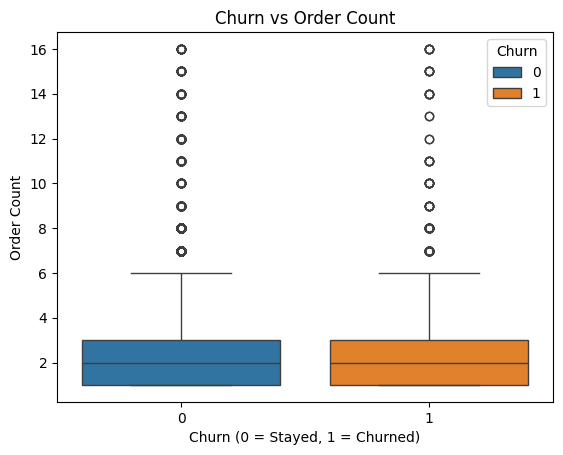

In [72]:
# Churn vs Order Count
sns.boxplot(x='Churn', y='OrderCount', data=data, hue='Churn')

plt.title('Churn vs Order Count')
plt.xlabel('Churn (0 = Stayed, 1 = Churned)')
plt.ylabel('Order Count')

plt.show()

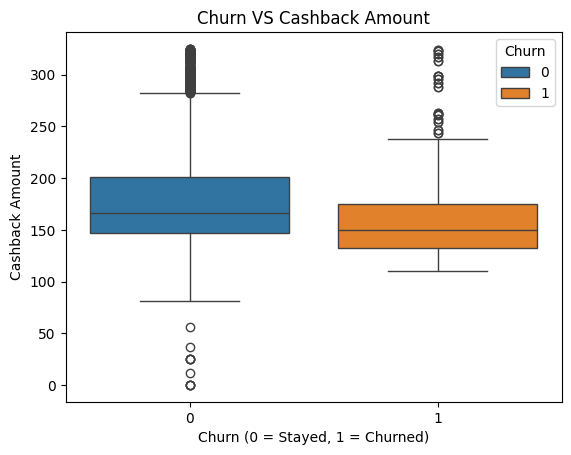

In [73]:
sns.boxplot(x='Churn',y='CashbackAmount', data=data, hue='Churn')
plt.title('Churn VS Cashback Amount')
plt.xlabel('Churn (0 = Stayed, 1 = Churned)')
plt.ylabel('Cashback Amount')
plt.show()

**Prepare Data for Machine Learning**

In [74]:
# remove Customer Id
data = data.drop('CustomerID', axis=1)

In [75]:
data.shape

(5630, 19)

**Separate X and y**

Remember:
X = input features
 / y = target we want to predict

In [76]:
x = data.drop('Churn',axis=1)
y = data['Churn']

In [77]:
print(x.shape)
print(y.shape)

(5630, 18)
(5630,)


to convert categorical column to numerical column We'll use **One-Hot Encoding**

In [78]:
# Check the columns automatically

num_col = x.select_dtypes(include='number').columns
cat_col = x.select_dtypes(include='str').columns

print("Numerical Cols :",num_col)
print("Categorical Cols :",cat_col)

Numerical Cols : Index(['Tenure', 'CityTier', 'WarehouseToHome', 'HourSpendOnApp',
       'NumberOfDeviceRegistered', 'SatisfactionScore', 'NumberOfAddress',
       'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount',
       'DaySinceLastOrder', 'CashbackAmount'],
      dtype='str')
Categorical Cols : Index(['PreferredLoginDevice', 'PreferredPaymentMode', 'Gender',
       'PreferedOrderCat', 'MaritalStatus'],
      dtype='str')


Now we'll convert the 5 categorical columns into numbers.We'll use ColumnTransformer and OneHotEncoder.

In [79]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [80]:
# Create the preprocessor
# Categorical columns -> OneHotEncoder -> Numbers -> Numerical columns -> Keep as they are
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_col)
    ],
    remainder='passthrough'
)

**Train/Test Split**

In [81]:
# 80% → Training data
# 20% → Testing data

# random_state=42 makes the split reproducible.

# stratify=y makes sure the training and testing sets have a similar proportion of:

# Stayed
# Churned

# This is particularly useful here because our target is imbalanced.

xtrain, xtest, ytrain, ytest = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [82]:
print(xtrain.shape)
print(xtest.shape)
print(ytrain.shape)
print(ytest.shape)

(4504, 18)
(1126, 18)
(4504,)
(1126,)


In [83]:
# fit → learns the categories from training data.
# transform → converts them into numbers.
xtrain_encoded = preprocessor.fit_transform(xtrain)
xtest_encoded = preprocessor.transform(xtest)

In [84]:
# Categorical values turned into columns
print(xtrain_encoded.shape)
print(xtest_encoded.shape)

(4504, 34)
(1126, 34)


**Logistic Regression**

because this is a binary classification problem : 
0 → Stayed / 
1 → Churned

In [85]:
from sklearn.linear_model import LogisticRegression

In [88]:
model = LogisticRegression(max_iter=2000)

In [89]:
# Train the Model
model.fit(xtrain_encoded,ytrain)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [ ]:
# Predict Model
ypred = model.predict(xtest_encoded)

In [91]:
print("Actual :",ytest.values[:10])
print("Predicted :",ypred[:10])

Actual : [0 0 0 0 0 0 0 0 0 0]
Predicted : [0 0 0 0 1 0 0 0 0 0]


In [92]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

1. Accuracy = 88.81% → Overall, the model predicted about 89% of customers correctly.
2. Precision = 73.88% → When the model says a customer will churn, about 74% actually churn.
3. Recall = 52.11% → The model finds about 52% of the customers who actually churn.
4. F1 = 61.11% → A combined measure of Precision and Recall.

For churn prediction, Recall is important because we want to identify customers who are actually going to leave.

In [93]:
accuracy = accuracy_score(ytest, ypred)
precision = precision_score(ytest, ypred)
recall = recall_score(ytest, ypred)
f1 = f1_score(ytest, ypred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Accuracy: 0.8880994671403197
Precision: 0.7388059701492538
Recall: 0.5210526315789473
F1 Score: 0.6111111111111112


**Confusion Matrix**

Now let's see exactly how many customers were:

1. Correctly predicted as Stayed
2. Correctly predicted as Churned
3. Incorrectly predicted as Churned
4. Incorrectly predicted as Stayed

In [94]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(ytest, ypred)
print(cm)

[[901  35]
 [ 91  99]]


|                      | Predicted Stayed | Predicted Churned |
| -------------------- | ---------------: | ----------------: |
| **Actually Stayed**  |              901 |                35 |
| **Actually Churned** |               91 |                99 |

2. Meaning of each number

901 — Correct Stayed

These 901 customers actually stayed, and our model correctly predicted 0.

35 — False Churn

These customers actually stayed, but the model predicted 1 (churn).

91 — Missed Churn

These customers actually churned, but the model predicted 0 (stayed).

This is particularly important because the model missed 91 customers who actually churned.

99 — Correct Churn

These 99 customers actually churned, and the model correctly predicted 1.

So:

Correct predictions = 901 + 99 = 1000
Wrong predictions   = 35 + 91 = 126

And:

1000 / 1126 ≈ 88.81%

which matches your accuracy. ✅

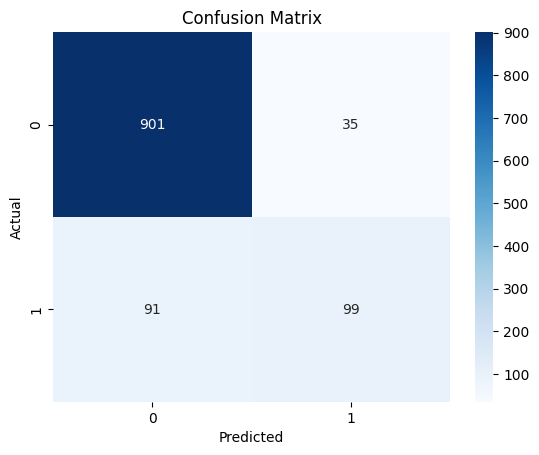

In [97]:
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

**second model: Random Forest Classifier**

In [98]:
from sklearn.ensemble import RandomForestClassifier

In [ ]:
# Model Created
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [100]:
# Train Model
rf_model.fit(xtrain_encoded,ytrain)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [101]:
# Predict
rf_pred = model.predict(xtest_encoded)

In [102]:
# Check result
print("Actual :",ytest.values[:10])
print("Predicted :",rf_pred[:10])

Actual : [0 0 0 0 0 0 0 0 0 0]
Predicted : [0 0 0 0 1 0 0 0 0 0]


In [103]:
rf_accuracy = accuracy_score(ytest, rf_pred)
rf_precision = precision_score(ytest, rf_pred)
rf_recall = recall_score(ytest, rf_pred)
rf_f1 = f1_score(ytest, rf_pred)

print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)

Accuracy : 0.8880994671403197
Precision: 0.7388059701492538
Recall   : 0.5210526315789473
F1 Score : 0.6111111111111112


In [104]:
rf_cm = confusion_matrix(ytest, rf_pred)

print(rf_cm)

[[901  35]
 [ 91  99]]


In [105]:
print(ytrain.value_counts())
print(ytest.value_counts())

Churn
0    3746
1     758
Name: count, dtype: int64
Churn
0    936
1    190
Name: count, dtype: int64


In [106]:
print(ytrain.value_counts(normalize=True) * 100)

Churn
0    83.170515
1    16.829485
Name: proportion, dtype: float64


In [107]:
model_balanced = LogisticRegression(
    max_iter=2000,
    class_weight='balanced'
)

In [108]:
model_balanced.fit(xtrain_encoded, ytrain)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Defaul

In [109]:
balanced_pred = model_balanced.predict(xtest_encoded)

In [110]:
balanced_accuracy = accuracy_score(ytest, balanced_pred)
balanced_precision = precision_score(ytest, balanced_pred)
balanced_recall = recall_score(ytest, balanced_pred)
balanced_f1 = f1_score(ytest, balanced_pred)

print("Accuracy :", balanced_accuracy)
print("Precision:", balanced_precision)
print("Recall   :", balanced_recall)
print("F1 Score :", balanced_f1)

Accuracy : 0.7921847246891652
Precision: 0.43956043956043955
Recall   : 0.8421052631578947
F1 Score : 0.5776173285198556


In [112]:
balanced_cm = confusion_matrix(ytest, balanced_pred)

print(balanced_cm)

[[732 204]
 [ 30 160]]


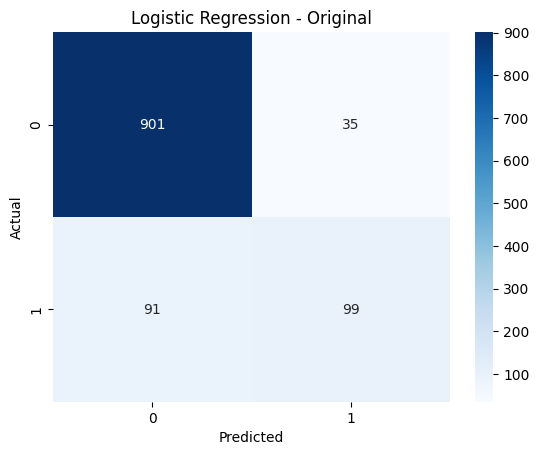

In [113]:
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Original")

plt.show()

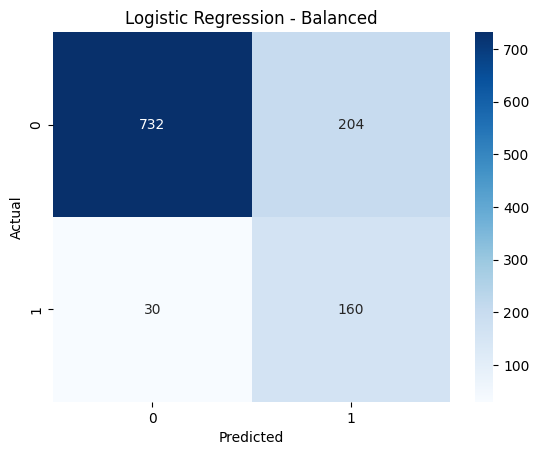

In [114]:
sns.heatmap(balanced_cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Logistic Regression - Balanced")

plt.show()

In [115]:
from sklearn.ensemble import GradientBoostingClassifier

In [116]:
gb_model = GradientBoostingClassifier(random_state=42)

In [117]:
gb_model.fit(xtrain_encoded, ytrain)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [118]:
gb_pred = gb_model.predict(xtest_encoded)

In [119]:
print("Actual   :", ytest.values[:10])
print("Predicted:", gb_pred[:10])

Actual   : [0 0 0 0 0 0 0 0 0 0]
Predicted: [0 0 0 0 0 0 0 0 0 0]


In [120]:
gb_accuracy = accuracy_score(ytest, gb_pred)
gb_precision = precision_score(ytest, gb_pred)
gb_recall = recall_score(ytest, gb_pred)
gb_f1 = f1_score(ytest, gb_pred)

print("Accuracy :", gb_accuracy)
print("Precision:", gb_precision)
print("Recall   :", gb_recall)
print("F1 Score :", gb_f1)

Accuracy : 0.9147424511545293
Precision: 0.8092105263157895
Recall   : 0.6473684210526316
F1 Score : 0.7192982456140351


| Model                        |   Accuracy |  Precision |     Recall |         F1 |
| ---------------------------- | ---------: | ---------: | ---------: | ---------: |
| Logistic Regression          |     88.81% |     73.88% |     52.11% |     61.11% |
| Random Forest                |     88.81% |     73.88% |     52.11% |     61.11% |
| Balanced Logistic Regression |     79.22% |     43.96% | **84.21%** |     57.76% |
| **Gradient Boosting**        | **91.47%** | **80.92%** | **64.74%** | **71.93%** |


In [122]:
gb_cm = confusion_matrix(ytest, gb_pred)

print(gb_cm)

[[907  29]
 [ 67 123]]


1. 907 → Stayed and correctly predicted as Stayed ✅
2. 29 → Stayed but incorrectly predicted as Churned
3. 67 → Churned but incorrectly predicted as Stayed
4. 123 → Churned and correctly predicted as Churned ✅

In [123]:
import joblib

In [124]:
# Save the model
joblib.dump(gb_model, "churn_model.pkl")

['churn_model.pkl']

In [125]:
# Save the preprocessor
joblib.dump(preprocessor, "churn_preprocessor.pkl")

['churn_preprocessor.pkl']

In [126]:
loaded_model = joblib.load("model/churn_model.pkl")
loaded_preprocessor = joblib.load("model/churn_preprocessor.pkl")

print("Model and preprocessor loaded successfully!")

Model and preprocessor loaded successfully!


In [127]:
# Test the loaded model
loaded_pred = loaded_model.predict(xtest_encoded)

In [128]:
print("Original predictions:", gb_pred[:10])
print("Loaded predictions  :", loaded_pred[:10])

Original predictions: [0 0 0 0 0 0 0 0 0 0]
Loaded predictions  : [0 0 0 0 0 0 0 0 0 0]


In [129]:
print(xtrain.columns.tolist())

['Tenure', 'PreferredLoginDevice', 'CityTier', 'WarehouseToHome', 'PreferredPaymentMode', 'Gender', 'HourSpendOnApp', 'NumberOfDeviceRegistered', 'PreferedOrderCat', 'SatisfactionScore', 'MaritalStatus', 'NumberOfAddress', 'Complain', 'OrderAmountHikeFromlastYear', 'CouponUsed', 'OrderCount', 'DaySinceLastOrder', 'CashbackAmount']
